# 03. Robustness: correlation importance vs. relative weights, and threshold stability

**Business question.** Can stakeholders trust the quadrant placements? Correlation-based importance is simple and
transparent, but attribute ratings are correlated with each other (halo), so a driver can look important only because
it travels with a real driver. Two checks:

1. **Relative weights** (Johnson, 2000), a Shapley-style decomposition of a multiple regression's R^2 into each
   driver's share, which accounts for correlated predictors. If correlation and relative weights rank drivers the same
   way, the simple metric is safe to use.
2. **Bootstrap** confidence intervals for each correlation and the share of resamples in which it clears r = 0.2,
   which shows which quadrant calls are borderline, particularly for the small payer sample.

A holdout check confirms the regression behind the relative weights generalises.

In [1]:
import os
# Single-threaded BLAS: avoids thread oversubscription and keeps timings reproducible on shared machines.
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "1")
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from plotting import apply_style, PALETTE
from generate_data import ATTRIBUTES, OUTCOME, OUTCOME_LABELS
apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)

RAW = Path("../data/raw/stakeholder_survey.csv")
PROCESSED = Path("../data/processed"); PROCESSED.mkdir(parents=True, exist_ok=True)
FIGS = Path("../reports/figures"); FIGS.mkdir(parents=True, exist_ok=True)
DRIVERS = list(ATTRIBUTES)
GROUPS = ["Physicians", "Pharmacists", "Patients", "Payers"]

from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from kda import driver_table, relative_weights, bootstrap_importance, IMPORTANCE_THRESHOLD

In [2]:
df = pd.read_csv(RAW)
groups = {g: df[df["stakeholder_group"] == g] for g in GROUPS}
tables = {g: driver_table(gdf, DRIVERS, OUTCOME) for g, gdf in groups.items()}

## Multicollinearity

Variance inflation factors show how much each attribute overlaps with the others. Values under 5 mean the regression
behind relative weights is well conditioned.

In [3]:
vif = {}
for g, gdf in groups.items():
    X = gdf[DRIVERS].fillna(gdf[DRIVERS].mean())
    X = np.column_stack([np.ones(len(X)), X.to_numpy()])
    vif[g] = [variance_inflation_factor(X, i) for i in range(1, X.shape[1])]
vif = pd.DataFrame(vif, index=DRIVERS)
vif.describe().loc[["mean", "max"]]

,Physicians,Pharmacists,Patients,Payers
mean,1.099,1.125,1.085,1.258
max,1.140,1.181,1.122,1.438


## Holdout check of the full regression

A linear regression of the outcome on all 24 ratings is fitted on 70% of each group and scored on the held-out 30%,
against a baseline that predicts the training mean, and against a single-driver model using only the top correlate.

In [4]:
rows = []
for g, gdf in groups.items():
    X = gdf[DRIVERS].fillna(gdf[DRIVERS].mean())
    y = gdf[OUTCOME]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42)
    full = LinearRegression().fit(Xtr, ytr)
    top = tables[g].index[0]
    single = LinearRegression().fit(Xtr[[top]], ytr)
    rows.append({"group": g, "n_test": len(yte),
                 "baseline_r2": r2_score(yte, np.full(len(yte), ytr.mean())),
                 f"top_driver_r2": r2_score(yte, single.predict(Xte[[top]])),
                 "all_drivers_r2_test": r2_score(yte, full.predict(Xte)),
                 "all_drivers_r2_train": r2_score(ytr, full.predict(Xtr))})
holdout = pd.DataFrame(rows).set_index("group")
holdout

,n_test,baseline_r2,top_driver_r2,all_drivers_r2_test,all_drivers_r2_train
group,,,,,
Physicians,180,-0.006,0.169,0.425,0.567
Pharmacists,120,-0.000,0.216,0.367,0.512
Patients,360,-0.014,0.246,0.522,0.495
Payers,45,-0.133,0.173,0.414,0.548


## Correlation vs. relative weights

In [5]:
compare = {}
for g, gdf in groups.items():
    rw = relative_weights(gdf, DRIVERS, OUTCOME)
    t = tables[g]
    c = pd.DataFrame({"importance_r": t["importance"], "rel_weight": rw, "rel_weight_pct": rw / rw.sum() * 100})
    c["rank_r"] = c["importance_r"].rank(ascending=False).astype(int)
    c["rank_rw"] = c["rel_weight"].rank(ascending=False).astype(int)
    c.attrs["r2"] = rw.attrs["r2"]
    compare[g] = c.sort_values("rank_r")

summary = []
for g, c in compare.items():
    k = (c["importance_r"] >= IMPORTANCE_THRESHOLD).sum()
    top_r = set(c.nsmallest(k, "rank_r").index)
    top_rw = set(c.nsmallest(k, "rank_rw").index)
    summary.append({"group": g, "model_r2": c.attrs["r2"],
                    "spearman_rank_corr": spearmanr(c["importance_r"], c["rel_weight"]).statistic,
                    "drivers_above_0.2": k, "same_drivers_in_top_k": len(top_r & top_rw),
                    "rw_share_of_drivers_above_0.2": c.loc[list(top_r), "rel_weight_pct"].sum()})
summary = pd.DataFrame(summary).set_index("group")
summary

,model_r2,spearman_rank_corr,drivers_above_0.2,same_drivers_in_top_k,rw_share_of_drivers_above_0.2
group,,,,,
Physicians,0.536,0.959,7,7,92.290
Pharmacists,0.489,0.812,6,5,87.618
Patients,0.509,0.977,6,6,89.770
Payers,0.574,0.647,6,6,87.424


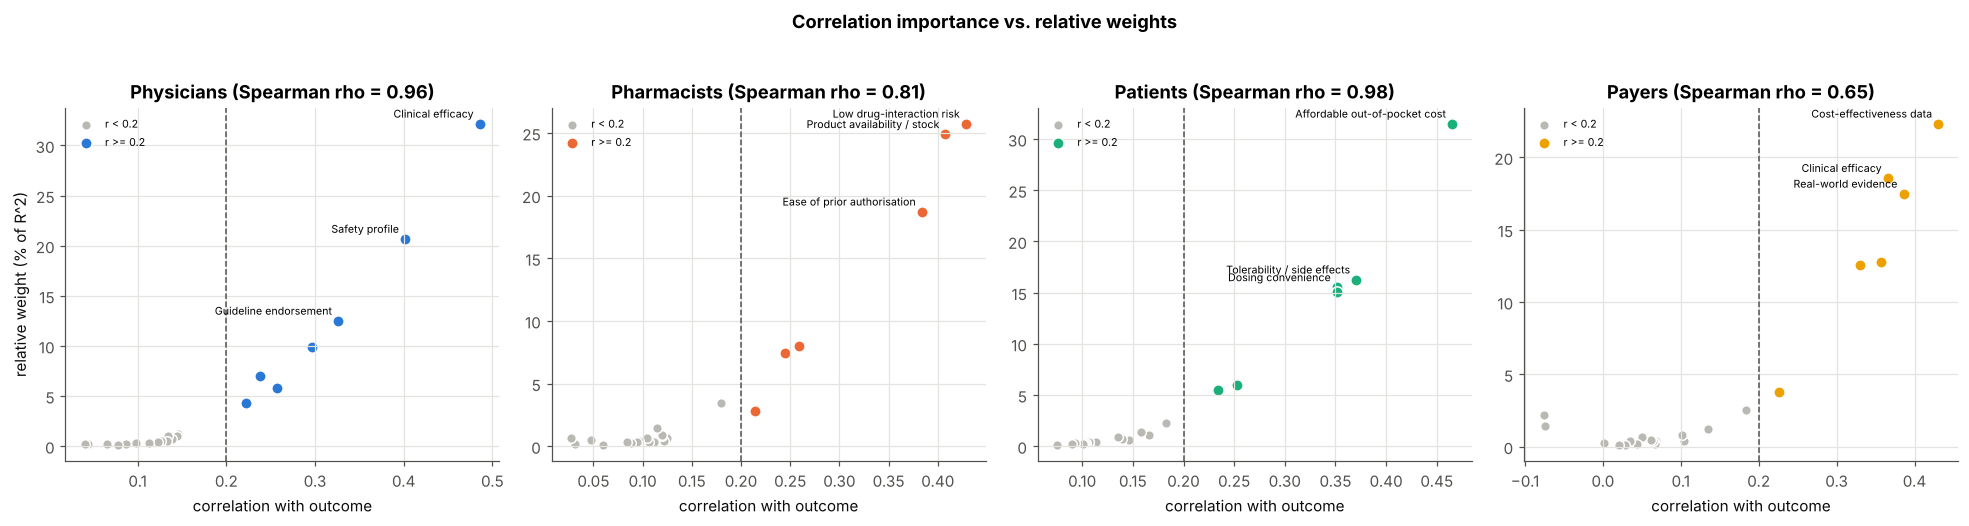

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (g, c), color in zip(axes, compare.items(), PALETTE):
    above = c["importance_r"] >= IMPORTANCE_THRESHOLD
    ax.scatter(c.loc[~above, "importance_r"], c.loc[~above, "rel_weight_pct"], s=40, color="#b9b8b3",
               edgecolor="white", label="r < 0.2")
    ax.scatter(c.loc[above, "importance_r"], c.loc[above, "rel_weight_pct"], s=55, color=color,
               edgecolor="white", label="r >= 0.2")
    ax.axvline(IMPORTANCE_THRESHOLD, color="#52514e", ls="--", lw=1)
    for d in c.index[:3]:
        ax.annotate(ATTRIBUTES[d], (c.loc[d, "importance_r"], c.loc[d, "rel_weight_pct"]), xytext=(-4, 4),
                    textcoords="offset points", fontsize=7, ha="right")
    rho = summary.loc[g, "spearman_rank_corr"]
    ax.set(title=f"{g} (Spearman rho = {rho:.2f})", xlabel="correlation with outcome",
           ylabel="relative weight (% of R^2)" if g == GROUPS[0] else "")
    ax.legend(fontsize=7, loc="upper left")
fig.suptitle("Correlation importance vs. relative weights", fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIGS / "03_correlation_vs_relative_weights.png")
plt.show()

In [7]:
side = pd.concat({g: c[["importance_r", "rank_r", "rel_weight_pct", "rank_rw"]].head(8) for g, c in compare.items()})
side

importance_r  rank_r  rel_weight_pct  rank_rw
Physicians  clinical_efficacy                   0.486       1          32.173        1
            safety_profile                      0.402       2          20.680        2
            guideline_endorsement               0.326       3          12.509        3
            prior_auth_ease                     0.296       4           9.908        4
            rep_knowledge                       0.257       5           5.757        6
            real_world_evidence                 0.238       6           6.966        5
            digital_resources                   0.222       7           4.297        7
            cost_effectiveness_data             0.146       8           1.227        8
Pharmacists drug_interactions                   0.429       1          25.741        1
            availability_in_stock               0.408       2          24.904        2
            prior_auth_ease                     0.384       3          18.723        3
            formulary_coverage                  0.259       4           8.001        4
            medical_info_responsiveness         0.245       5           7.458        5
            digital_resources                   0.214       6           2.790        7
            rep_knowledge                       0.180       7           3.429        6
            adherence_tools                     0.125       8           0.612       14
Patients    out_of_pocket_cost                  0.465       1          31.501        1
            tolerability                        0.371       2          16.275        2
            dosing_convenience                  0.351       3          15.523        3
            patient_support_program             0.351       4          15.033        4
            ease_of_administration              0.252       5           5.948        5
            speed_of_onset                      0.234       6           5.491        6
            adherence_tools                     0.183       7           2.243        7
            peer_recommendation                 0.166       8           1.102        9
Payers      cost_effectiveness_data             0.431       1          22.332        1
            real_world_evidence                 0.386       2          17.487        3
            clinical_efficacy                   0.366       3          18.574        2
            durability_of_response              0.357       4          12.736        4
            value_for_money                     0.330       5          12.539        5
            patient_support_program             0.226       6           3.756        6
            prior_auth_ease                     0.184       7           2.538        7
            medical_info_responsiveness         0.134       8           1.219       10

## Bootstrap stability of the 0.2 threshold

500 bootstrap resamples per group. A driver is a **stable** call if it lands on the same side of r = 0.2 in at least
90% of resamples; otherwise it is flagged **borderline** and its hypothesis should be read with that caveat.

In [8]:
boot = {}
for g, gdf in groups.items():
    b = bootstrap_importance(gdf, DRIVERS, OUTCOME, n_boot=500, seed=1)
    b["importance_r"] = tables[g]["importance"]
    b["quadrant"] = tables[g]["quadrant"]
    above = b["importance_r"] >= IMPORTANCE_THRESHOLD
    b["stable"] = np.where(above, b["share_above_threshold"] >= 0.9, b["share_above_threshold"] <= 0.1)
    boot[g] = b

stability = pd.DataFrame({g: {"drivers": len(b), "stable_calls": int(b["stable"].sum()),
                              "borderline_calls": int((~b["stable"]).sum()),
                              "median_ci_width": (b["ci_high"] - b["ci_low"]).median()}
                          for g, b in boot.items()}).T
stability

,drivers,stable_calls,borderline_calls,median_ci_width
Physicians,24.000,22.000,2.000,0.158
Pharmacists,24.000,20.000,4.000,0.194
Patients,24.000,21.000,3.000,0.112
Payers,24.000,19.000,5.000,0.312


In [9]:
borderline = pd.concat({g: b[~b["stable"]][["importance_r", "ci_low", "ci_high", "share_above_threshold", "quadrant"]]
                        for g, b in boot.items()})
borderline

importance_r  ci_low  ci_high  share_above_threshold        quadrant
Physicians  real_world_evidence                 0.238   0.168    0.310                  0.850  Priority fixes
            digital_resources                   0.222   0.144    0.309                  0.702  Priority fixes
Pharmacists formulary_coverage                  0.259   0.152    0.355                  0.864  Priority fixes
            rep_knowledge                       0.180   0.070    0.277                  0.350        Maintain
            medical_info_responsiveness         0.245   0.135    0.347                  0.798       Strengths
            digital_resources                   0.214   0.126    0.303                  0.622       Strengths
Patients    speed_of_onset                      0.234   0.179    0.281                  0.888  Priority fixes
            adherence_tools                     0.183   0.124    0.238                  0.266    Low priority
            peer_recommendation                 0.166   0.109    0.224                  0.126        Maintain
Payers      formulary_coverage                  0.104  -0.045    0.256                  0.102    Low priority
            prior_auth_ease                     0.184   0.035    0.349                  0.428    Low priority
            patient_support_program             0.226   0.083    0.363                  0.658  Priority fixes
            medical_info_responsiveness         0.134  -0.029    0.277                  0.224        Maintain
            educational_materials               0.102  -0.060    0.270                  0.148    Low priority

In [10]:
out = pd.concat([pd.concat([compare[g], boot[g][["ci_low", "ci_high", "share_above_threshold", "stable"]]], axis=1)
                 .assign(group=g) for g in GROUPS]).rename_axis("driver").reset_index()
out.to_csv(PROCESSED / "robustness_checks.csv", index=False)
print(f"saved {len(out)} rows")

saved 96 rows


## Findings

* Multicollinearity is low (mean VIF 1.09 to 1.26, max 1.44), so the relative-weight regression is well conditioned.
* On a 30% holdout, the all-driver regression explains 0.37 to 0.52 of outcome variance (Physicians 0.425,
  Pharmacists 0.367, Patients 0.522, Payers 0.414), against roughly 0 for the mean baseline and 0.17 to 0.25 for
  the single strongest driver.
* **Correlation and relative weights agree.** Spearman rank correlation across all 24 drivers: Physicians 0.96,
  Patients 0.98, Pharmacists 0.81, Payers 0.65 (the lower values come from reshuffling among near-zero drivers). For
  the drivers above r = 0.2, the same set appears in the relative-weight top-k in Physicians (7 of 7), Patients
  (6 of 6) and Payers (6 of 6), and 5 of 6 for Pharmacists, where digital resources (rank 7 by weight) swaps with
  field rep knowledge.
* Drivers above the threshold carry 87% to 92% of each group's explained variance.
* Bootstrap (500 resamples): 82 of 96 driver-group calls are stable. The 14 borderline calls sit close to r = 0.2;
  the small payer sample has the widest intervals (median CI width 0.31 vs. 0.11 for patients) and the most
  borderline calls (5). Payers' patient support programme (r = 0.226, CI 0.08 to 0.36) is the weakest priority fix.